# Pilot: weighted selector and adaptive querying

A small test of two new seed-selection rules. The code is in `pilot_new_rules.py`; this notebook runs it and compares the results with round 1 on the same graph pairs.

**1. Weighted selector** (GOAT on Chung–Lu and PAPER, percolation on ER and PAPER).
- **Score:** a seed set's score is the core-panel logistic score: seed degree, harmonic, pair mass and signature uniqueness (cap 3), weighted as fitted on the random sets of the training collection. These are the same models as `core_panel_refit.ipynb`; section 1 checks that.
- **Selection:** seeds are added one at a time. Seed j is the candidate that gives the highest score, chosen from either
  - **`weighted_2j`:** the 2j highest-degree unused vertices, as in round 1;
  - **`weighted_all`:** every unused vertex.
- **Comparison:** top degree, random, and the round-1 winner for that setting (hub-free distinguishing for GOAT, clustered for percolation), all from round 1.

**2. Adaptive querying** (GOAT on Chung–Lu and PAPER). Query some seeds, run GOAT, check, repeat.
- **Detecting success:** a run counts as a success when its objective reaches 0.41 × (|E(A)| + |E(B)|). In round 1, every success scored at least 0.46 and every failure at most 0.36, so no truth is needed. Section 4 checks this.
- **Variants:** all start from the first seeds of hub-free distinguishing (4 on Chung–Lu, 6 on PAPER) and add one query at a time until success is detected (at most 20 / 16 queries):
  - **`stop`:** the next query is the next vertex of hub-free distinguishing;
  - **`uncertainty`:** the next query is the vertex GOAT was least sure about in the last run, among the 2j highest-degree unused vertices outside the top 10. It uses the largest entry of the vertex's row in GOAT's final soft matching, or edge consistency if that is unavailable;
  - **`retry`:** like `stop`, but before each new query GOAT is rerun on two leave-one-out subsets of the seeds already bought. Those reruns cost no queries.
- **Metric:** queries until detected success.

**Scale and time.**
- **Pairs:** GOAT uses round-1 pairs 1–10 and percolation pairs 1–20; each pair is regenerated and checked against its round-1 hashes.
- **Run time:** about 20–30 minutes with 3 jobs in parallel. Progress goes to `logs/pilot_*.log`, and results are saved after every pair, so rerunning resumes.

**Caveats.**
- These pairs were already used in round 1, and hub-free distinguishing was chosen as the base rule after seeing round 1.
- Anything promising needs confirming on fresh pairs.

In [1]:
import json
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest

EXPERIMENT_DIR = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir()) / 'selection_rule_comparison'
if EXPERIMENT_DIR.name != 'selection_rule_comparison':
    EXPERIMENT_DIR = EXPERIMENT_DIR / 'selection_rule_comparison'
REPO_ROOT = EXPERIMENT_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from selection_rule_comparison.archive import pilot_new_rules as pilot
from selection_rule_comparison import settings as S
from selection_rule_comparison.strategies import STRATEGY_CODES, GraphA, ordering, seed_set_features

RUN_EXPERIMENTS = True   # False: only analyse saved results
JOBS = 3                 # graph models run in parallel
N_BOOTSTRAP = 2000
OUT, ROUND1 = pilot.OUTPUT_DIR, pilot.ROUND1_DIR
rng = np.random.default_rng(2026)

WINNER = {'goat': 'hub_free_distinguishing', 'percolation': 'clustered'}
LABELS = {'random': 'random', 'top_degree': 'top degree', 'clustered': 'clustered',
          'hub_free_distinguishing': 'hub-free distinguishing', 'weighted_2j': 'weighted (2j pool)',
          'weighted_all': 'weighted (all vertices)'}
COLORS = {'random': '#9e9e9e', 'top_degree': '#222222', 'clustered': '#1f77b4', 'hub_free_distinguishing': '#9467bd',
          'weighted_2j': '#d62728', 'weighted_all': '#ff7f0e'}
MODEL_LABELS = {'sparse_er': 'ER', 'paper_pa': 'PAPER', 'chung_lu': 'Chung-Lu'}
print('Results folder:', OUT)

Results folder: /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/data/pilot_new_rules


## 1. The weights

The first row of each setting holds the weights the selector uses: log-odds per SD of the training random sets, for the raw features. The second row is the same fitted model written with the three non-degree features adjusted for degree. It should match the core-panel refit table:
- GOAT Chung–Lu: −0.18, −0.16, +0.04, +0.42;
- GOAT PAPER: +0.47, −0.17, +0.06, +0.13;
- percolation ER: +0.64, −0.05, +0.60, +0.33;
- percolation PAPER: +0.63, +0.56, +0.94, −0.18.

Both rows describe the same model. The raw weights differ because the features are correlated with degree.

In [2]:
fits = {(a, m): pilot.fit_weights(a, m) for a, m in pilot.WEIGHTED_CELLS}
rows = []
for (a, m), fit in fits.items():
    for name, key in [('raw features (used)', 'weight_per_sd'), ('degree-adjusted (refit table)', 'degree_adjusted_per_sd')]:
        rows.append({'setting': f'{a} · {MODEL_LABELS[m]}', 'weights': name,
                     **{f[2:]: round(fit[key][f], 2) for f in pilot.FEATURES},
                     'training seeds': fit['n_seeds'], 'training success': round(fit['success_rate'], 2)})
display(pd.DataFrame(rows).set_index(['setting', 'weights']))

degree  harmonic  \
setting             weights                                           
goat · Chung-Lu     raw features (used)             -0.03     -0.35   
                    degree-adjusted (refit table)   -0.18     -0.16   
goat · PAPER        raw features (used)              0.81     -0.58   
                    degree-adjusted (refit table)    0.47     -0.17   
percolation · ER    raw features (used)             -0.01     -0.13   
                    degree-adjusted (refit table)    0.64     -0.05   
percolation · PAPER raw features (used)             -1.00      1.36   
                    degree-adjusted (refit table)    0.63      0.56   

                                                   pair_mass  signature_r3  \
setting             weights                                                  
goat · Chung-Lu     raw features (used)                 0.08          0.43   
                    degree-adjusted (refit table)       0.04          0.42   
goat · PAPER        raw features (used)                 0.09          0.20   
                    degree-adjusted (refit table)       0.06          0.13   
percolation · ER    raw features (used)                 0.68          0.55   
                    degree-adjusted (refit table)       0.60          0.33   
percolation · PAPER raw features (used)                 1.08         -0.22   
                    degree-adjusted (refit table)       0.94         -0.18   

                                                   training seeds  \
setting             weights                                         
goat · Chung-Lu     raw features (used)                         9   
                    degree-adjusted (refit table)               9   
goat · PAPER        raw features (used)                        12   
                    degree-adjusted (refit table)              12   
percolation · ER    raw features (used)                         8   
                    degree-adjusted (refit table)               8   
percolation · PAPER raw features (used)                         7   
                    degree-adjusted (refit table)               7   

                                                   training success  
setting             weights                                          
goat · Chung-Lu     raw features (used)                        0.67  
                    degree-adjusted (refit table)              0.67  
goat · PAPER        raw features (used)                        0.27  
                    degree-adjusted (refit table)              0.27  
percolation · ER    raw features (used)                        0.51  
                    degree-adjusted (refit table)              0.51  
percolation · PAPER raw features (used)                        0.61  
                    degree-adjusted (refit table)              0.61

## 2. What the selectors pick (pair 1, middle budget)

This is a quick look before the run, on the first round-1 pair of each setting. It also confirms that the pairs regenerate exactly; a mismatch with round 1 raises an error. For each rule it shows the mean seed degree, the share of seeds shared with top degree, and three features.

In [3]:
preview = []
for (a, m), fit in fits.items():
    seed, A, B, truth = pilot.load_pair(a, m, 0)
    graph = GraphA(A)
    unit = {f: fit['weight_per_sd'][f] / fit['sd'][f] for f in pilot.FEATURES}
    budgets = sorted(S.default_budgets('main', a, m))
    k = budgets[len(budgets) // 2]
    td = ordering('top_degree', graph, k, np.random.default_rng([S.STRATEGY_SEED_BASE, seed, STRATEGY_CODES['top_degree']]))
    sets = {'top degree': td}
    for i, pool in enumerate(pilot.POOLS):
        order = pilot.weighted_ordering(graph, unit, k, pool, np.random.default_rng([S.STRATEGY_SEED_BASE, seed, 100 + i]))
        sets[LABELS[f'weighted_{pool}']] = order[:k]
    for name, chosen in sets.items():
        f = seed_set_features(graph, np.sort(chosen))
        preview.append({'setting': f'{a} · {MODEL_LABELS[m]}', 'seeds': k, 'rule': name,
                        'mean seed degree': graph.degree[chosen].mean(),
                        'shared with top degree': len(set(chosen.tolist()) & set(td.tolist())) / k,
                        'pair mass': f['f_pair_mass'], 'signature r3': f['f_signature_r3'], 'harmonic': f['f_harmonic']})
display(pd.DataFrame(preview).set_index(['setting', 'seeds', 'rule']).round(3))

mean seed degree  \
setting             seeds rule                                        
goat · Chung-Lu     10    top degree                         70.700   
                          weighted (2j pool)                 51.100   
                          weighted (all vertices)             6.700   
goat · PAPER        10    top degree                         35.000   
                          weighted (2j pool)                 33.700   
                          weighted (all vertices)            33.200   
percolation · ER    6     top degree                         22.333   
                          weighted (2j pool)                 21.333   
                          weighted (all vertices)            10.333   
percolation · PAPER 6     top degree                         34.333   
                          weighted (2j pool)                 27.667   
                          weighted (all vertices)            21.000   

                                                   shared with top degree  \
setting             seeds rule                                              
goat · Chung-Lu     10    top degree                                1.000   
                          weighted (2j pool)                        0.400   
                          weighted (all vertices)                   0.000   
goat · PAPER        10    top degree                                1.000   
                          weighted (2j pool)                        0.500   
                          weighted (all vertices)                   0.400   
percolation · ER    6     top degree                                1.000   
                          weighted (2j pool)                        0.500   
                          weighted (all vertices)                   0.000   
percolation · PAPER 6     top degree                                1.000   
                          weighted (2j pool)                        0.500   
                          weighted (all vertices)                   0.167   

                                                   pair mass  signature r3  \
setting             seeds rule                                               
goat · Chung-Lu     10    top degree                   0.631         0.407   
                          weighted (2j pool)           0.419         0.597   
                          weighted (all vertices)      0.003         0.261   
goat · PAPER        10    top degree                   0.119         0.725   
                          weighted (2j pool)           0.129         0.776   
                          weighted (all vertices)      0.125         0.763   
percolation · ER    6     top degree                   0.025         0.108   
                          weighted (2j pool)           0.032         0.138   
                          weighted (all vertices)      0.027         0.057   
percolation · PAPER 6     top degree                   0.027         0.057   
                          weighted (2j pool)           0.040         0.089   
                          weighted (all vertices)      0.056         0.096   

                                                   harmonic  
setting             seeds rule                               
goat · Chung-Lu     10    top degree                321.900  
                          weighted (2j pool)        301.817  
                          weighted (all vertices)   216.808  
goat · PAPER        10    top degree                277.717  
                          weighted (2j pool)        273.542  
                          weighted (all vertices)   271.608  
percolation · ER    6     top degree                249.833  
                          weighted (2j pool)        246.375  
                          weighted (all vertices)   211.700  
percolation · PAPER 6     top degree                270.097  
                          weighted (2j pool)        260.708  
                          weighted (all vertices)   250.778

## 3. Run the pilot

This takes about 20–30 minutes with `JOBS = 3`. To follow progress, `tail -f` the log files listed below. If the run stops, rerun this cell: finished pairs are kept. Set `RUN_EXPERIMENTS = False` to analyse saved results only.

In [4]:
if RUN_EXPERIMENTS:
    pilot.run_all(jobs=JOBS)

2026-10-21T02:46:19-04:00 running 6 jobs, 3 at a time. Progress logs:
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/pilot_adaptive_goat_chung_lu.log
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/pilot_adaptive_goat_paper_pa.log
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/pilot_weighted_goat_chung_lu.log
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/pilot_weighted_goat_paper_pa.log
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/pilot_weighted_percolation_sparse_er.log
    tail -f /Users/langsong/Desktop/Seeded-Graph-Matching/selection_rule_comparison/logs/pilot_weighted_percolation_paper_pa.log
2026-10-21T02:52:24-04:00 weighted goat/chung_lu finished in 6.0 min
2026-10-21T02:53:27-04:00 adaptive goat/paper_pa finished in 7.0 min
2026-10-21T02:55:36-04:00 weighted percolatio

## 4. Weighted selector against round 1

**Comparison against top degree and against the round-1 winner on the same pairs.**
- **k\*:** the first budget on the round-1 grid at which a rule succeeds. "Fewer / same / more" counts pairs where the weighted rule needed fewer, the same or more queries than the reference.
- **Mean success difference:** the paired difference in mean success over the grid, with a 95% bootstrap interval over pairs.

In [5]:
def flag(series):
    return series.astype(str).str.strip().str.lower().isin(['true', '1', '1.0'])


def round1_success(algorithm, model, pairs, strategies):
    runs = pd.read_csv(ROUND1 / algorithm / model / 'runs.csv')
    runs = runs[runs['pair_index'].isin(pairs) & runs['strategy'].isin(strategies)]
    runs = runs.assign(success=flag(runs['success']))
    return runs.groupby(['pair_index', 'strategy', 'budget'], as_index=False)['success'].any()


def k_star(ev):
    budgets = sorted(ev['budget'].unique())
    censor = budgets[-1] + (budgets[-1] - budgets[-2])
    table = {}
    for strategy, part in ev.groupby('strategy'):
        matrix = part.pivot(index='pair_index', columns='budget', values='success').sort_index(axis=1)
        table[strategy] = matrix.apply(lambda r: next((b for b, v in r.items() if v), censor), axis=1)
    return pd.DataFrame(table), censor


def paired(ev, ks, strategy, reference):
    d = ks[strategy] - ks[reference]
    fewer, same, more = int((d < 0).sum()), int((d == 0).sum()), int((d > 0).sum())
    grid = ev.pivot_table(index='pair_index', columns='strategy', values='success', aggfunc='mean')
    g = (grid[strategy] - grid[reference]).to_numpy()
    boot = rng.choice(g, size=(N_BOOTSTRAP, len(g))).mean(axis=1)
    return {'fewer / same / more': f'{fewer} / {same} / {more}',
            'sign-test p': round(binomtest(fewer, fewer + more).pvalue, 3) if fewer + more else np.nan,
            'mean success difference': f'{g.mean():+.2f} [{np.percentile(boot, 2.5):+.2f}, {np.percentile(boot, 97.5):+.2f}]'}


weighted_ev, comparisons, feature_rows = {}, [], []
for a, m in pilot.WEIGHTED_CELLS:
    path = OUT / f'weighted_{a}_{m}.csv'
    if not path.exists():
        print('No results yet for', a, m)
        continue
    w = pd.read_csv(path)
    w['success'] = flag(w['success'])
    pairs = sorted(w['pair_index'].unique())
    base = round1_success(a, m, pairs, ['random', 'top_degree', WINNER[a]])
    ev = pd.concat([base, w[['pair_index', 'strategy', 'budget', 'success']]], ignore_index=True)
    weighted_ev[(a, m)] = ev
    ks, _ = k_star(ev)
    setting = f'{a} · {MODEL_LABELS[m]}'
    for strategy in ['weighted_2j', 'weighted_all']:
        for reference in ['top_degree', WINNER[a]]:
            comparisons.append({'setting': setting, 'pairs': len(pairs),
                                'comparison': f'{LABELS[strategy]} vs {LABELS[reference]}',
                                **paired(ev, ks, strategy, reference)})
    # Seed-set features at the middle budget
    budgets = sorted(ev['budget'].unique())
    k = budgets[len(budgets) // 2]
    r1 = pd.read_csv(ROUND1 / a / m / 'runs.csv')
    r1 = r1[r1['pair_index'].isin(pairs) & r1['strategy'].isin(['top_degree', WINNER[a]]) & r1['budget'].eq(k)]
    r1 = r1.drop_duplicates(['pair_index', 'strategy'])
    both = pd.concat([r1, w[w['budget'].eq(k)]], ignore_index=True)
    both = both.assign(success=flag(both['success']))
    for strategy, part in both.groupby('strategy'):
        feature_rows.append({'setting': setting, 'seeds': k, 'rule': LABELS[strategy],
                             'success': part['success'].mean(), 'seed degree': part['f_degree'].mean(),
                             'harmonic': part['f_harmonic'].mean(), 'pair mass': part['f_pair_mass'].mean(),
                             'signature r3': part['f_signature_r3'].mean()})

display(pd.DataFrame(comparisons).set_index(['setting', 'pairs', 'comparison']))
print('Seed-set features at the middle budget (means over pairs):')
display(pd.DataFrame(feature_rows).set_index(['setting', 'seeds', 'rule']).round(3))

fewer / same / more  \
setting             pairs comparison                                                               
goat · Chung-Lu     10    weighted (2j pool) vs top degree                             8 / 0 / 2   
                          weighted (2j pool) vs hub-free distinguishing                4 / 3 / 3   
                          weighted (all vertices) vs top degree                        3 / 3 / 4   
                          weighted (all vertices) vs hub-free distinguishing           2 / 3 / 5   
goat · PAPER        10    weighted (2j pool) vs top degree                             6 / 2 / 2   
                          weighted (2j pool) vs hub-free distinguishing                2 / 3 / 5   
                          weighted (all vertices) vs top degree                        6 / 2 / 2   
                          weighted (all vertices) vs hub-free distinguishing           2 / 3 / 5   
percolation · ER    20    weighted (2j pool) vs top degree                             9 / 9 / 2   
                          weighted (2j pool) vs clustered                              5 / 9 / 6   
                          weighted (all vertices) vs top degree                       2 / 4 / 14   
                          weighted (all vertices) vs clustered                        2 / 0 / 18   
percolation · PAPER 20    weighted (2j pool) vs top degree                             6 / 8 / 6   
                          weighted (2j pool) vs clustered                             5 / 3 / 12   
                          weighted (all vertices) vs top degree                        7 / 8 / 5   
                          weighted (all vertices) vs clustered                         4 / 7 / 9   

                                                                              sign-test p  \
setting             pairs comparison                                                        
goat · Chung-Lu     10    weighted (2j pool) vs top degree                          0.109   
                          weighted (2j pool) vs hub-free distinguishing             1.000   
                          weighted (all vertices) vs top degree                     1.000   
                          weighted (all vertices) vs hub-free distinguishing        0.453   
goat · PAPER        10    weighted (2j pool) vs top degree                          0.289   
                          weighted (2j pool) vs hub-free distinguishing             0.453   
                          weighted (all vertices) vs top degree                     0.289   
                          weighted (all vertices) vs hub-free distinguishing        0.453   
percolation · ER    20    weighted (2j pool) vs top degree                          0.065   
                          weighted (2j pool) vs clustered                           1.000   
                          weighted (all vertices) vs top degree                     0.004   
                          weighted (all vertices) vs clustered                      0.000   
percolation · PAPER 20    weighted (2j pool) vs top degree                          1.000   
                          weighted (2j pool) vs clustered                           0.143   
                          weighted (all vertices) vs top degree                     0.774   
                          weighted (all vertices) vs clustered                      0.267   

                                                                             mean success difference  
setting             pairs comparison                                                                  
goat · Chung-Lu     10    weighted (2j pool) vs top degree                      +0.28 [+0.17, +0.40]  
                          weighted (2j pool) vs hub-free distinguishing         -0.00 [-0.13, +0.13]  
                          weighted (all vertices) vs top degree                 +0.08 [-0.13, +0.33]  
                          weighted (all vertices) vs hub-free distinguishing    -0.20 

Seed-set features at the middle budget (means over pairs):


success  seed degree  \
setting             seeds rule                                            
goat · Chung-Lu     10    hub-free distinguishing     0.80       37.570   
                          top degree                  0.20       66.560   
                          weighted (2j pool)          0.80       50.280   
                          weighted (all vertices)     0.30        6.840   
goat · PAPER        10    hub-free distinguishing     0.80       24.670   
                          top degree                  0.50       34.170   
                          weighted (2j pool)          0.70       33.930   
                          weighted (all vertices)     0.70       33.850   
percolation · ER    6     clustered                   0.90       21.033   
                          top degree                  0.80       21.742   
                          weighted (2j pool)          0.95       20.817   
                          weighted (all vertices)     0.30        9.667   
percolation · PAPER 6     clustered                   0.90       31.567   
                          top degree                  0.80       34.967   
                          weighted (2j pool)          0.95       28.692   
                          weighted (all vertices)     0.95       16.292   

                                                   harmonic  pair mass  \
setting             seeds rule                                           
goat · Chung-Lu     10    hub-free distinguishing   290.076      0.240   
                          top degree                322.977      0.654   
                          weighted (2j pool)        303.334      0.431   
                          weighted (all vertices)   216.625      0.007   
goat · PAPER        10    hub-free distinguishing   263.367      0.078   
                          top degree                279.719      0.119   
                          weighted (2j pool)        276.083      0.135   
                          weighted (all vertices)   275.731      0.133   
percolation · ER    6     clustered                 246.641      0.034   
                          top degree                248.188      0.020   
                          weighted (2j pool)        245.927      0.033   
                          weighted (all vertices)   212.696      0.027   
percolation · PAPER 6     clustered                 264.444      0.048   
                          top degree                271.601      0.032   
                          weighted (2j pool)        262.463      0.043   
                          weighted (all vertices)   243.934      0.051   

                                                   signature r3  
setting             seeds rule                                   
goat · Chung-Lu     10    hub-free distinguishing         0.657  
                          top degree                      0.370  
                          weighted (2j pool)              0.568  
                          weighted (all vertices)         0.260  
goat · PAPER        10    hub-free distinguishing         0.809  
                          top degree                      0.712  
                          weighted (2j pool)              0.771  
                          weighted (all vertices)         0.771  
percolation · ER    6     clustered                       0.109  
                          top degree                      0.097  
                          weighted (2j pool)              0.115  
                          weighted (all vertices)         0.055  
percolation · PAPER 6     clustered                       0.106  
                          top degree                      0.076  
                          weighted (2j pool)              0.100  
                          weighted (all vertices)         0.079

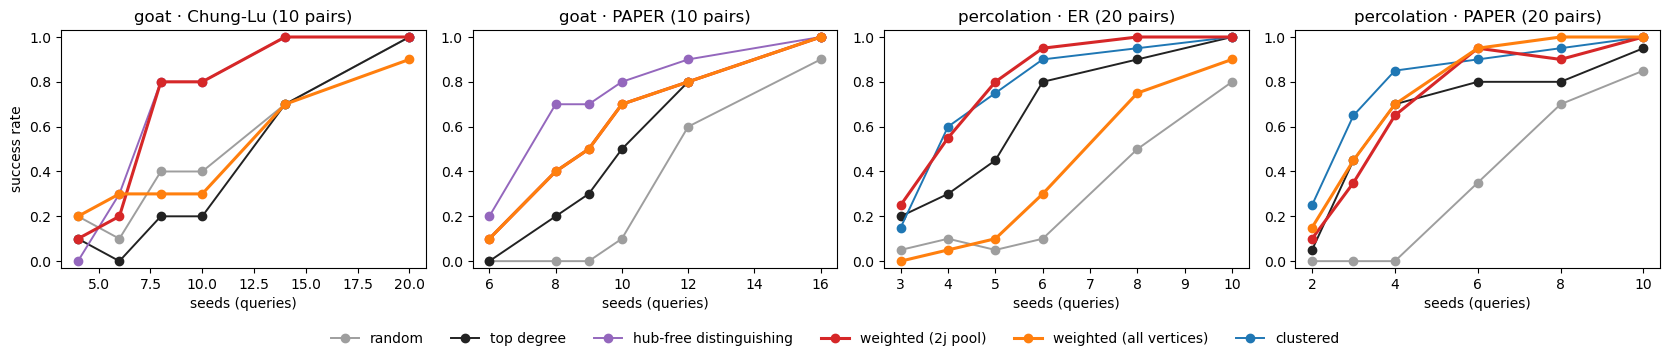

In [6]:
if weighted_ev:
    fig, axes = plt.subplots(1, len(weighted_ev), figsize=(4.2 * len(weighted_ev), 3.6), squeeze=False)
    for ax, ((a, m), ev) in zip(axes[0], weighted_ev.items()):
        curve = ev.groupby(['strategy', 'budget'])['success'].mean().unstack()
        for strategy in ['random', 'top_degree', WINNER[a], 'weighted_2j', 'weighted_all']:
            if strategy in curve.index:
                ax.plot(curve.columns, curve.loc[strategy], marker='o', color=COLORS[strategy], label=LABELS[strategy],
                        linewidth=2.2 if strategy.startswith('weighted') else 1.4)
        ax.set_title(f"{a} · {MODEL_LABELS[m]} ({ev['pair_index'].nunique()} pairs)")
        ax.set_xlabel('seeds (queries)')
        ax.set_ylim(-0.03, 1.03)
    axes[0, 0].set_ylabel('success rate')
    handles, labels = [], []
    for ax in axes[0]:
        for h, l in zip(*ax.get_legend_handles_labels()):
            if l not in labels:
                handles.append(h)
                labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=len(labels), frameon=False)
    plt.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

## 5. Adaptive querying with GOAT

**Detection check.** Every GOAT run in this pilot is cross-tabulated: did the objective declare success, and was accuracy really at least 0.9? Off-diagonal counts mean false or missed detections.

**Consistency check.** The `stop` variant reruns hub-free distinguishing at round-1 budgets. Those runs should reproduce round 1 exactly.

In [7]:
summaries, run_tables = [], []
for m in pilot.ADAPTIVE_MODELS:
    p, r = OUT / f'adaptive_goat_{m}.csv', OUT / f'adaptive_goat_{m}_runs.csv'
    if p.exists():
        summaries.append(pd.read_csv(p).assign(model=MODEL_LABELS[m], model_key=m))
        run_tables.append(pd.read_csv(r).assign(model=MODEL_LABELS[m], model_key=m))
if not summaries:
    raise FileNotFoundError('No adaptive results yet: run section 3.')
summary = pd.concat(summaries, ignore_index=True)
runs = pd.concat(run_tables, ignore_index=True)
for column in ['detected', 'success']:
    runs[column] = flag(runs[column])
for column in ['detected', 'true_success', 'censored']:
    summary[column] = flag(summary[column])

unique_runs = runs.drop_duplicates(['model', 'pair_index', 'seed_vertices', 'kind'])
print('Detection check (unique GOAT runs):')
display(pd.crosstab([unique_runs['model'], unique_runs['detected'].rename('objective says success')],
                    unique_runs['success'].rename('accuracy >= 0.9')))

agree = []
for m in pilot.ADAPTIVE_MODELS:
    mine = runs[runs['model_key'].eq(m) & runs['variant'].eq('stop') & runs['kind'].eq('main')]
    r1 = pd.read_csv(ROUND1 / 'goat' / m / 'runs.csv')
    r1 = r1[r1['strategy'].eq(pilot.BASE_RULE)][['pair_index', 'budget', 'final_unseeded_accuracy']]
    merged = mine.merge(r1, left_on=['pair_index', 'n_seeds'], right_on=['pair_index', 'budget'])
    if len(merged):
        agree.append({'model': MODEL_LABELS[m], 'runs compared': len(merged),
                      'same accuracy as round 1': float(np.isclose(merged['accuracy'], merged['final_unseeded_accuracy']).mean())})
display(pd.DataFrame(agree))

Detection check (unique GOAT runs):


accuracy >= 0.9                  False  True 
model    objective says success              
Chung-Lu False                     136      0
         True                        0     23
PAPER    False                      83      0
         True                        0     19

,model,runs compared,same accuracy as round 1
0,Chung-Lu,26,1.0
1,PAPER,21,1.0


**Queries until detected success.**
- **Never detected:** a pair where success was never detected within the budget is counted as max + 1 and marked as never detected.
- **False stops:** detections where accuracy was below 0.9.
- **GOAT runs:** the computing cost, including free retries.
- **Round-1 columns:** k\* of the fixed rules on round 1's coarser grid, for reference. The fair comparison for the adaptive variants is `stop`, which steps one query at a time.

In [8]:
summary['false_stop'] = summary['detected'] & ~summary['true_success']
overview = summary.groupby(['model', 'variant'], sort=False).agg(
    pairs=('queries', 'size'), mean_queries=('queries', 'mean'), median_queries=('queries', 'median'),
    never_detected=('censored', 'sum'), false_stops=('false_stop', 'sum'), mean_goat_runs=('runs_used', 'mean'),
    mean_seed_degree=('mean_seed_degree', 'mean'))
display(overview.round(2))

queries = summary.pivot_table(index=['model', 'pair_index'], columns='variant', values='queries')[list(pilot.ADAPTIVE_VARIANTS)]
reference = []
for m in pilot.ADAPTIVE_MODELS:
    pairs = sorted(summary.loc[summary['model_key'].eq(m), 'pair_index'].unique())
    if not pairs:
        continue
    ev = round1_success('goat', m, pairs, ['random', 'top_degree', pilot.BASE_RULE])
    ks, _ = k_star(ev)
    ks.columns = [f'round 1 grid: {LABELS.get(c, c)}' for c in ks.columns]
    ks.index = pd.MultiIndex.from_product([[MODEL_LABELS[m]], ks.index], names=['model', 'pair_index'])
    reference.append(ks)
display(queries.join(pd.concat(reference)) if reference else queries)

tests = []
for model, part in queries.groupby(level='model'):
    for variant in ['uncertainty', 'retry']:
        d = part[variant] - part['stop']
        fewer, same, more = int((d < 0).sum()), int((d == 0).sum()), int((d > 0).sum())
        tests.append({'model': model, 'comparison': f'{variant} vs stop', 'fewer / same / more': f'{fewer} / {same} / {more}',
                      'sign-test p': round(binomtest(fewer, fewer + more).pvalue, 3) if fewer + more else np.nan,
                      'mean difference in queries': round(d.mean(), 2)})
display(pd.DataFrame(tests).set_index(['model', 'comparison']))

pairs  mean_queries  median_queries  never_detected  \
model    variant                                                            
Chung-Lu stop            10           7.7             7.0               0   
         uncertainty     10           7.9             8.0               0   
         retry           10           7.4             7.0               0   
PAPER    stop            10           8.2             7.5               0   
         uncertainty     10           8.7             8.5               0   
         retry           10           8.1             7.5               0   

                      false_stops  mean_goat_runs  mean_seed_degree  
model    variant                                                     
Chung-Lu stop                   0             4.7             39.88  
         uncertainty            0             4.9             39.41  
         retry                  0            11.7             40.14  
PAPER    stop                   0             3.2             25.25  
         uncertainty            0             3.7             25.11  
         retry                  0             7.4             25.27

stop  uncertainty  retry  \
model    pair_index                             
Chung-Lu 0            7.0         11.0    6.0   
         1            6.0          8.0    6.0   
         2            6.0          6.0    6.0   
         3            7.0          9.0    7.0   
         4           11.0          5.0   11.0   
         5            8.0          8.0    8.0   
         6            7.0          7.0    7.0   
         7           11.0         10.0   10.0   
         8            8.0         10.0    7.0   
         9            6.0          5.0    6.0   
PAPER    0            9.0         11.0    9.0   
         1            8.0         10.0    8.0   
         2           11.0         11.0   10.0   
         3           13.0         12.0   13.0   
         4            8.0          8.0    8.0   
         5            7.0          7.0    7.0   
         6            7.0          7.0    7.0   
         7            6.0          6.0    6.0   
         8            6.0          6.0    6.0   
         9            7.0          9.0    7.0   

                     round 1 grid: hub-free distinguishing  \
model    pair_index                                          
Chung-Lu 0                                               8   
         1                                               6   
         2                                               6   
         3                                               8   
         4                                              14   
         5                                               8   
         6                                               8   
         7                                              14   
         8                                               8   
         9                                               6   
PAPER    0                                               9   
         1                                               8   
         2                                              12   
         3                                              16   
         4                                               8   
         5                                               8   
         6                                               8   
         7                                               6   
         8                                               6   
         9                                               8   

                     round 1 grid: random  round 1 grid: top degree  
model    pair_index                                                  
Chung-Lu 0                             20                        20  
         1                             20                        14  
         2                              8                        14  
         3                             14                        20  
         4                             14                         4  
         5                             20                        20  
         6                              8                        14  
         7                              4                         8  
         8                              8                        14  
         9                              4                         8  
PAPER    0                             12                         9  
         1                             12                        10  
         2                             10                        10  
         3                             16                        12  
         4                             20                        16  
         5                             12                        10  
         6                             16                        10  
         7                             12                         8  
         8                             12                         8  
         9                             16                        12

fewer / same / more  sign-test p  \
model    comparison                                             
Chung-Lu uncertainty vs stop           3 / 3 / 4        1.000   
         retry vs stop                 3 / 7 / 0        0.250   
PAPER    uncertainty vs stop           1 / 6 / 3        0.625   
         retry vs stop                 1 / 9 / 0        1.000   

                              mean difference in queries  
model    comparison                                       
Chung-Lu uncertainty vs stop                         0.2  
         retry vs stop                              -0.3  
PAPER    uncertainty vs stop                         0.5  
         retry vs stop                              -0.1

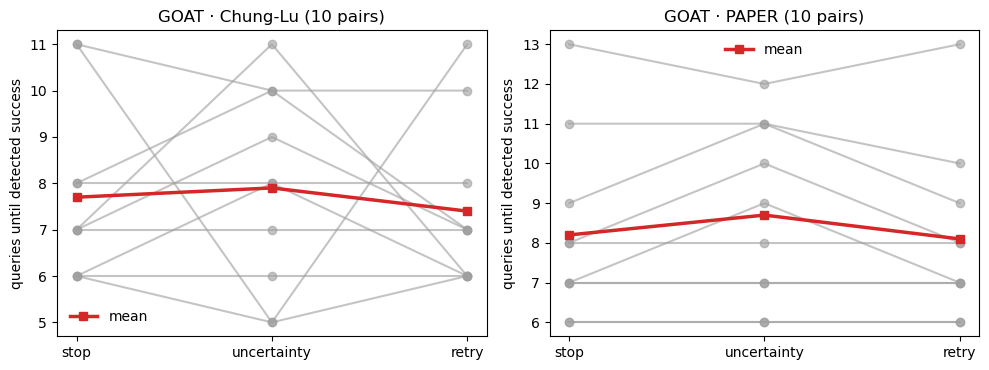

In [9]:
fig, axes = plt.subplots(1, queries.index.get_level_values('model').nunique(), figsize=(10, 3.8), squeeze=False)
for ax, (model, part) in zip(axes[0], queries.groupby(level='model')):
    x = np.arange(len(pilot.ADAPTIVE_VARIANTS))
    for _, row in part.iterrows():
        ax.plot(x, row.to_numpy(float), color='#9e9e9e', alpha=0.6, marker='o')
    ax.plot(x, part.mean().to_numpy(float), color='#d62728', marker='s', linewidth=2.5, label='mean')
    ax.set_xticks(x, pilot.ADAPTIVE_VARIANTS)
    ax.set_title(f'GOAT · {model} ({len(part)} pairs)')
    ax.set_ylabel('queries until detected success')
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Reading the results

**Weighted selector.**
- **Does it work?** It is promising if `weighted_2j` matches or beats the round-1 winner in each setting. That would mean one rule with fitted weights replaces a menu of hand-made rules.
- **What to expect:** the refit weights favour pair mass for percolation and signature uniqueness for GOAT Chung–Lu. For GOAT PAPER they mostly favour degree, so they may miss the gain hub-free distinguishing found there.
- **`weighted_all`:** this shows what happens when the model is free to leave the region it was trained on. Watch its mean seed degree in section 4.

**Adaptive querying.**
- **The baseline:** `stop` is hub-free distinguishing with stopping at every budget.
- **`uncertainty`:** it helps if it needs fewer queries than `stop` on most pairs.
- **`retry`:** it helps if leave-one-out reruns turn some failures into detected successes at no extra query cost. Its extra GOAT runs are the price.
- **Detection:** false stops should be zero. If not, raise `pilot.DETECTION_RATIO` and rerun.

**Next.** Rules that look good here should be rerun on fresh pairs, a new pair stream, before drawing conclusions.